# 3장 불확실성 샘플링

최소 신뢰도, 마진, 엔트로피 세 전략을 2장의 `query_fn` 모양으로 구현하고 Random과 비교한다.

- 3.1 불확실성 샘플링의 원리
- 3.2 최소 신뢰도(least confidence)
- 3.3 마진 샘플링(margin sampling)
- 3.4 엔트로피 샘플링(entropy sampling)
- 3.5 세 전략의 학습 곡선 비교
- 3.6 샘플링 편향과 콜드 스타트 문제

CPU만으로 돈다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, **kw):
    oracle = make_sim_oracle(data["y_pool"])
    frames = []
    for name, query_fn in strategies.items():
        for s in seeds:
            df, _ = run_loop(query_fn, oracle, data, s, **kw)
            frames.append(df.assign(strategy=name))
        print(f"{data['name']:5s} {name:14s} 완료")
    return pd.concat(frames, ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


## 3.2 최소 신뢰도(least confidence)

가장 높은 클래스 확률이 낮을수록 불확실하다고 본다. 점수 함수는 모두 「클수록 먼저 고른다」로 방향을 맞춘다.

In [2]:
# ── 불확실성 점수 함수: 최소 신뢰도 ────
def score_lc(P):
    return 1 - P.max(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

## 3.3 마진 샘플링(margin sampling)

1위와 2위 확률의 차가 작을수록 불확실하다. 방향을 맞추려고 차에 음수를 붙인다.

In [3]:
# ── 불확실성 점수 함수: 마진 ────
def score_margin(P):
    s = np.sort(P, 1)
    return -(s[:, -1] - s[:, -2])

## 3.4 엔트로피 샘플링(entropy sampling)

확률 분포 전체의 엔트로피를 점수로 쓴다.

In [4]:
# ── 불확실성 점수 함수: 엔트로피 ────
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

SCORES = {"최소 신뢰도": score_lc, "마진": score_margin, "엔트로피": score_entropy}

## 3.5 세 전략의 학습 곡선 비교

먼저 클래스 3개의 확률 단체 위에서 세 점수의 등고선을 그려 모양 차이를 본다. 그다음 두 데이터에서 Random을 포함한 네 전략을 시드 5개로 비교한다.

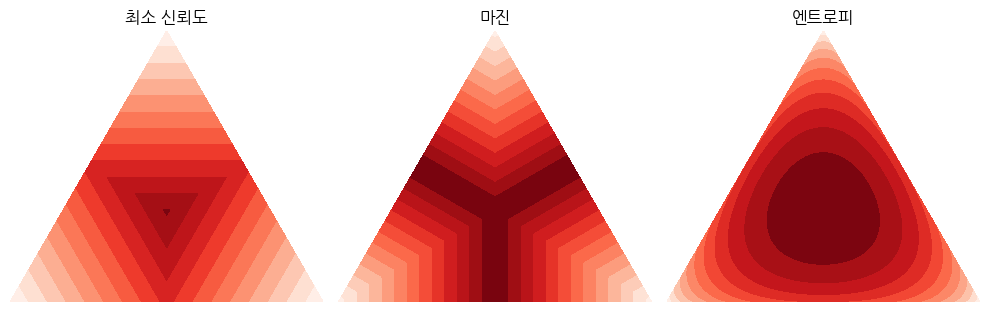

In [5]:
# ── 확률 단체 위의 점수 등고선 ────
a, b = np.meshgrid(np.linspace(0, 1, 201), np.linspace(0, 1, 201))
mask = a + b <= 1
P3 = np.stack([a[mask], b[mask], 1 - a[mask] - b[mask]], 1)
xs, ys = P3[:, 1] + P3[:, 2] / 2, P3[:, 2] * np.sqrt(3) / 2

fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for ax, (title, fn) in zip(axes, SCORES.items()):
    ax.tricontourf(xs, ys, fn(P3), levels=12, cmap="Reds")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.axis("off")
fig.tight_layout()
fig.savefig("out/ch03_simplex_scores.png", dpi=200)

In [6]:
# ── 네 전략 비교 실험 ────
STRATEGIES = {"엔트로피": make_score_query(score_entropy), "마진": make_score_query(score_margin),
              "최소 신뢰도": make_score_query(score_lc), "Random": query_random}
res = {name: run_strategies(STRATEGIES, d) for name, d in DATA.items()}
for name, r in res.items():
    r.to_csv(f"results/ch03_{name}.csv", index=False)

nsmc  엔트로피           완료


nsmc  마진             완료


nsmc  최소 신뢰도         완료


nsmc  Random         완료


ynat  엔트로피           완료


ynat  마진             완료


ynat  최소 신뢰도         완료


ynat  Random         완료


In [7]:
# ── 기준선 대조: 2장 Random과 같은지 확인 ────
for name, r in res.items():
    prev = pd.read_csv(f"results/ch02_random_{name}.csv")
    now = r[r.strategy == "Random"]
    print(name, "2장 대비 F1 최대 차이:", np.abs(prev.f1.values - now.f1.values).max())

nsmc 2장 대비 F1 최대 차이: 5.551115123125783e-17
ynat 2장 대비 F1 최대 차이: 8.326672684688674e-17



nsmc 정확도
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.7491   0.0051 0.7861 1.2121   0.0039
      마진 0.7491   0.0051 0.7861 1.2121   0.0035
  최소 신뢰도 0.7491   0.0051 0.7861 1.2121   0.0036
  Random 0.7447   0.0020 0.7803 1.0000   0.0000

nsmc 매크로 F1
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.7479   0.0055 0.7860 1.2121   0.0039
      마진 0.7479   0.0055 0.7860 1.2121   0.0035
  최소 신뢰도 0.7479   0.0055 0.7860 1.2121   0.0036
  Random 0.7426   0.0034 0.7802 1.0000   0.0000

ynat 정확도
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.6221   0.0069 0.7268 2.3529   0.0079
      마진 0.6034   0.0114 0.7011 2.0000   0.0080
  최소 신뢰도 0.6138   0.0031 0.7271 2.2222   0.0071
  Random 0.5082   0.0080 0.6374 1.0000   0.0000

ynat 매크로 F1
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.6164   0.0048 0.7202 2.0000   0.0079
      마진 0.6084   0.0086 0.7032 1.9048   0.0080
  최소 신뢰도 0.6134   0.0031 0.7205 1.9048   0.0071
  Random 0.5335   0.0068 0.6500 1.0000   0

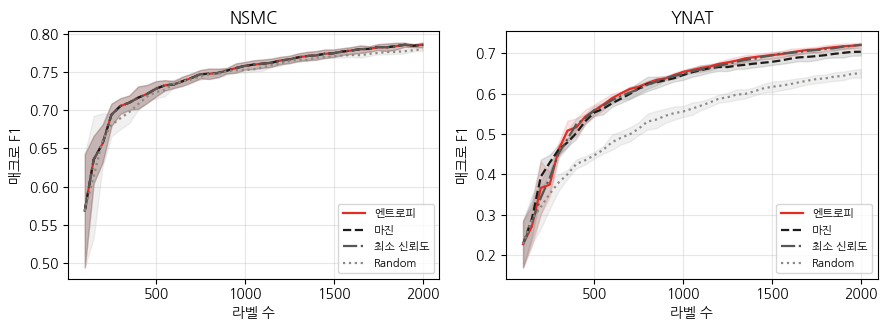

In [8]:
# ── 학습 곡선과 지표 표 ────
for name, r in res.items():
    for metric in ("acc", "f1"):
        print(f"\n{name} {LABEL[metric]}")
        print(summarize(r, metric).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    plot_curves(r, "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch03_curves.png", dpi=200)

In [9]:
# ── 이진 분류 동치 확인 ────
for name, d in DATA.items():
    idx = np.random.default_rng(0).choice(len(d["y_pool"]), N_INIT, replace=False)
    P = proba(train_model(d["X_pool"][idx], d["y_pool"][idx], 0), d["X_pool"], d["n_classes"])
    S = pd.DataFrame({k: fn(P) for k, fn in SCORES.items()})
    top = {k: set(np.argsort(-v.values)[:K]) for k, v in S.items()}
    print(f"\n{name} 점수 순위 상관(Spearman)")
    print(S.corr(method="spearman").round(4))
    print("상위 50개 겹침:", {f"{p}∩{q}": len(top[p] & top[q])
                            for p, q in [("최소 신뢰도", "마진"), ("최소 신뢰도", "엔트로피"), ("마진", "엔트로피")]})


nsmc 점수 순위 상관(Spearman)
        최소 신뢰도   마진  엔트로피
최소 신뢰도     1.0  1.0   1.0
마진         1.0  1.0   1.0
엔트로피       1.0  1.0   1.0
상위 50개 겹침: {'최소 신뢰도∩마진': 50, '최소 신뢰도∩엔트로피': 50, '마진∩엔트로피': 50}



ynat 점수 순위 상관(Spearman)
        최소 신뢰도      마진    엔트로피
최소 신뢰도  1.0000  0.9014  0.9135
마진      0.9014  1.0000  0.7175
엔트로피    0.9135  0.7175  1.0000
상위 50개 겹침: {'최소 신뢰도∩마진': 3, '최소 신뢰도∩엔트로피': 26, '마진∩엔트로피': 0}


## 3.6 샘플링 편향과 콜드 스타트 문제

YNAT에서 라운드마다 고른 50개의 클래스 비율을 엔트로피와 Random으로 비교한다. 그다음 초기 라벨을 20개로 줄였을 때 엔트로피가 Random보다 나빠지는지 확인한다.

풀 클래스 비율: {'IT과학': 0.1146, '경제': 0.13395, '사회': 0.11235, '생활문화': 0.1259, '세계': 0.18215, '스포츠': 0.1695, '정치': 0.16155}


엔트로피 라운드 평균 비율: {'IT과학': 0.133, '경제': 0.138, '사회': 0.176, '생활문화': 0.146, '세계': 0.147, '스포츠': 0.132, '정치': 0.128}


Random 라운드 평균 비율: {'IT과학': 0.117, '경제': 0.128, '사회': 0.105, '생활문화': 0.135, '세계': 0.187, '스포츠': 0.17, '정치': 0.158}


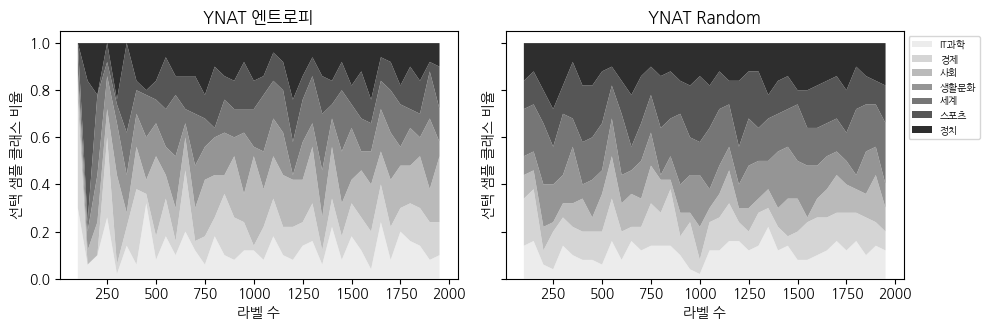

In [10]:
# ── 선택 샘플의 클래스 분포 ────
import json
YNAT_NAMES = json.load(open("data/ynat_labels.json"))
d = DATA["ynat"]
print("풀 클래스 비율:", dict(zip(YNAT_NAMES, np.bincount(d["y_pool"]) / len(d["y_pool"]))))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, name in zip(axes, ["엔트로피", "Random"]):
    _, idx_l = run_loop(STRATEGIES[name], make_sim_oracle(d["y_pool"]), d, 0)
    q = d["y_pool"][idx_l[N_INIT:]].reshape(-1, K)
    frac = np.stack([np.bincount(r, minlength=d["n_classes"]) / K for r in q])
    print(name, "라운드 평균 비율:", dict(zip(YNAT_NAMES, frac.mean(0).round(3))))
    ax.stackplot(N_INIT + K * np.arange(len(frac)), frac.T, labels=YNAT_NAMES,
                 colors=plt.cm.Greys(np.linspace(0.15, 0.85, d["n_classes"])))
    ax.set(title=f"YNAT {name}", xlabel="라벨 수", ylabel="선택 샘플 클래스 비율")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig("out/ch03_class_drift.png", dpi=200)

In [11]:
# ── 콜드 스타트 실험 ────
COLD = {"엔트로피": STRATEGIES["엔트로피"], "Random": query_random}
cold = {name: run_strategies(COLD, d, n_init=20) for name, d in DATA.items()}
for name, r in cold.items():
    r.to_csv(f"results/ch03_cold_{name}.csv", index=False)
    print(f"\n{name} 초기 라벨 20개 (F1)")
    print(summarize(r, "f1").to_string(index=False))
    print(r.groupby(["strategy", "n_labeled"]).f1.mean().unstack(0).iloc[:6].round(4))

nsmc  엔트로피           완료


nsmc  Random         완료


ynat  엔트로피           완료


ynat  Random         완료

nsmc 초기 라벨 20개 (F1)
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.7286   0.0043 0.7854 1.0152   0.0032
  Random 0.7335   0.0025 0.7827 1.0000   0.0000
strategy   Random    엔트로피
n_labeled                
20         0.3451  0.3451
70         0.5692  0.3622
120        0.5951  0.5603
170        0.6379  0.6505
220        0.6620  0.6686
270        0.6752  0.6887

ynat 초기 라벨 20개 (F1)
strategy    ALC  ALC_std  final     LE  t_query
    엔트로피 0.5785   0.0052 0.7162 1.9608   0.0084
  Random 0.5072   0.0117 0.6457 1.0000   0.0000
strategy   Random    엔트로피
n_labeled                
20         0.0444  0.0444
70         0.1432  0.1040
120        0.2074  0.1725
170        0.2731  0.2433
220        0.3177  0.3268
270        0.3562  0.3764
